# Limit Shape

Sea
$$B_\mu = \{x \in \mathbb{R}^d \mid \mu(x) \leq 1\}$$
la bola unitaria en norma $\mu(\cdot)$, y considerar el conjunto aleatorio
$$B(t) = \{x\in \mathbb{R}^d \mid T(0, \lfloor x \rfloor) \leq t\}.$$
Cox y Durret [1] probaron que si

(1) $F(0) < p_c$, y

(2) Dadas $2d$ copias independientes $t_1,...,t_{2d}$ de los pesos, tenemos $\mathbb{E} \min\{t_1^d,...,t_{2d}^d\} < \infty$,

entonces para todo $\epsilon>0$ tenemos que, c.s., 
$$(1-\epsilon) B_\mu \subseteq \frac{B(t)}{t} \subseteq (1+\epsilon) B_\mu$$
para todo $t>0$ suficiéntemente grande. En virtud de este teorema, llamamos a $B_\mu$ la *limit shape* del modelo.


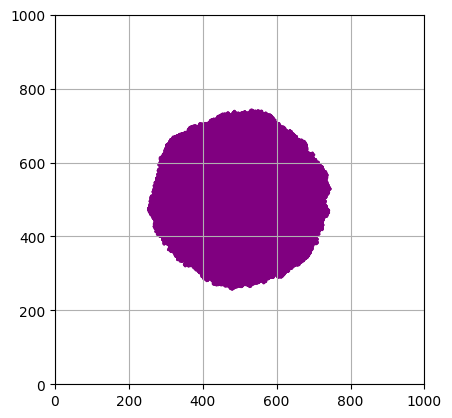

In [3]:
from utils import grid_canvas, dijkstra, fpp
from itertools import product
from random import expovariate, binomialvariate

n = 1000
m = 500

pesos = fpp(n, n, lambda: expovariate(1))
dists, ancest = dijkstra(n, n, pesos, (m, m))

diam = 100
bola = [a for a in product(range(0, n + 1), range(0, n + 1)) if dists[*a] <= diam]
grid_canvas(n, n, bola, [], 'purple')

Se conjetura que, para pesos con distribución absolutamente continua, la limit shape es estrictamente convexa. En particular, su borde no debería contener segmentos rectos. Se conocen, sin embargo, ejemplos no triviales de distribuciones para las cuales esto último ocurre. En particular, Durrett y Liggett [2] probaron que en $d=2$, si la distribución de los pesos tiene soporte en $[1, \infty)$ y $\mathbb{P}(\omega_e = 1)$ es mayor al threshold de percolación dirigida en $\mathbb{Z}^2$, entonces la frontera de la limit shape contiene segmentos rectos.

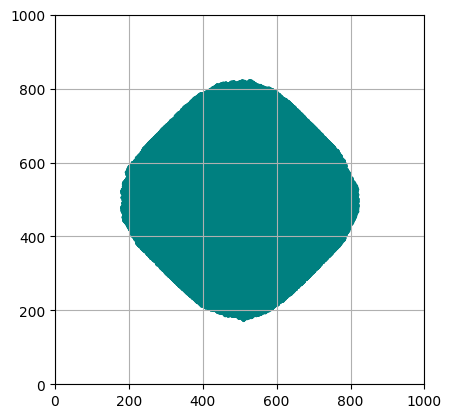

In [5]:
def flat_edge_distribution():
    moneda = binomialvariate(1, 0.67) # mayor al threshold de percolación dirigida
    if moneda: return 1
    else: return 1 + expovariate(0.1)

n = 1000
m = 500

pesos = fpp(n, n, flat_edge_distribution)
dists, ancest = dijkstra(n, n, pesos, (m, m))

diam = 400
bola = [a for a in product(range(0, n + 1), range(0, n + 1)) if dists[*a] <= diam]
grid_canvas(n, n, bola, [], 'teal')

### Referencias

[1] Cox, J. T. and Durrett, R. (1981). Some limit theorems for percolation with neces-
sary and suﬃcient conditions. Annals of Probab., 9, 583–603.

[2] Durrett, R. and Liggett, T. (1981). The shape of the limit set in Richardson’s growth
model. Annals of Probab., 9, 186–193.